# COFW preprocessing and preparation

The dataset is obtained from: https://data.caltech.edu/records/bc0bf-nc666

Dataset structure:
```text
|----COFW
|----train
|----|---image_0.jpg
|----|---image_1.jpg
|----|---pts_0.jpg
|----|---pts_1.jpg
|----|---......
|----test
|----|---image_0.jpg
|----|---image_1.jpg
|----|---pts_0.jpg
|----|---pts_1.jpg
|----|---......

In [1]:
import numpy as np, os, PIL.Image as Image, pandas as pd, scipy, cv2, matplotlib.pyplot as plt
os.chdir('..')
from utility_scripts.landmark_utilities import preprocess_face_image_and_landmarks

In [2]:

cofw_symmetric_pairs_horizontal_flipping = [ # extracted visually
    (0, 1),   # Outer eyebrows
    (2, 3),   # Inner eyebrows
    (4, 6),   # Top eyebrows
    (5, 7),   # Bottom eyebrows
    (8, 9),   # Outer eye corners
    (10, 11), # Inner eye corners
    (12, 14), # Top eyelids
    (13, 15), # Bottom eyelids
    (16, 17), # Pupils (Center of eyes)
    (18, 19), # Outer nose/nostrils
    (22, 23)  # Outer mouth corners
]
# Points 20, 21 (Nose bridge/tip) and 24, 25, 26, 27 (Lips center), and 28 (Chin) 
# automatically stay in place because they are not in this list.


cofw_symmetric_pairs_horizontal_flipping = np.array(cofw_symmetric_pairs_horizontal_flipping)
cofw_symmetric_pairs_horizontal_flipping = np.concat((cofw_symmetric_pairs_horizontal_flipping, cofw_symmetric_pairs_horizontal_flipping[:, ::-1])) # generate the full index translation by adding the flipped pairs
input_indices = cofw_symmetric_pairs_horizontal_flipping[:, 0]
output_indices = cofw_symmetric_pairs_horizontal_flipping[:, 1]

flipped_indices = np.arange(start = 0, stop = 29, step = 1)
for i in range(29):
    if i in input_indices:
        flipped_indices[i] = output_indices[input_indices == i]
    else:
        flipped_indices[i] = i


print('Index mapping for horizontal flipping (acquired visually)')
for i in range(len(flipped_indices)):
    print(f'{i} :: {flipped_indices[i]}')


Index mapping for horizontal flipping (acquired visually)
0 :: 1
1 :: 0
2 :: 3
3 :: 2
4 :: 6
5 :: 7
6 :: 4
7 :: 5
8 :: 9
9 :: 8
10 :: 11
11 :: 10
12 :: 14
13 :: 15
14 :: 12
15 :: 13
16 :: 17
17 :: 16
18 :: 19
19 :: 18
20 :: 20
21 :: 21
22 :: 23
23 :: 22
24 :: 24
25 :: 25
26 :: 26
27 :: 27
28 :: 28


/tmp/ipykernel_8319/523087560.py:26: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  flipped_indices[i] = output_indices[input_indices == i]


In [2]:
dataset_dir = os.path.join('data', 'datasets', 'visibility detection', 'COFW')
os.path.exists(dataset_dir)

True

In [4]:
train_folder = os.path.join(dataset_dir, 'train')
test_folder = os.path.join(dataset_dir, 'test')


In [5]:
def draw_landmarks(image, landmarks, visibility, draw_text = False):
    image = np.array(image)
    for i, ((x, y), visible) in enumerate(zip(landmarks, visibility)):
        if not visible:
            image = cv2.circle(image, (int(x), int(y)), radius = 0, color = (0, 255, 0), thickness = 2)
        else:
            image = cv2.circle(image, (int(x), int(y)), radius = 0, color = (0, 0, 255), thickness = 2)
        if draw_text:
            cv2.putText(image, str(i), (int(x)+2, int(y)+2), cv2.FONT_HERSHEY_SIMPLEX, 1, (255, 0, 0), 1)
    return image

In [6]:
output_images_dir = os.path.join(dataset_dir, 'Images')
os.makedirs(output_images_dir, exist_ok = True)

landmarks_list = []
visibility_list = []
image_names = []
training_split = []
image_size = 224

In [7]:
i = 0
for filename in os.listdir(train_folder):
    if filename.endswith('.jpg'):
        file_number = filename.replace('.jpg', '').replace('image_', '')
        image_path = os.path.join(train_folder, f'image_{file_number}.jpg')
        pts_file = pd.read_excel(os.path.join(train_folder, f'pts{file_number}.xlsx'), header = None)

        landmarks, visibility = pts_file.values[:, :2], pts_file.values[:, 2]
        image = cv2.imread(image_path)
        preprocessed_image, preprocessed_landmarks = preprocess_face_image_and_landmarks(image, landmarks, padding = 1.5, target_size = image_size)
        
        flipped_image = preprocessed_image[:, ::-1, :]
        flipped_landmarks = preprocessed_landmarks.copy()
        flipped_landmarks[:, 0] = image_size - flipped_landmarks[:, 0]
        flipped_landmarks, flipped_visibility = flipped_landmarks[flipped_indices], visibility[flipped_indices]
        
        cv2.imwrite(os.path.join(output_images_dir, f'{i}_original.jpg'), preprocessed_image)
        cv2.imwrite(os.path.join(output_images_dir, f'{i}_flipped.jpg'), flipped_image)
        landmarks_list.append(preprocessed_landmarks)
        visibility_list.append(visibility)
        landmarks_list.append(flipped_landmarks)
        visibility_list.append(flipped_visibility)
        image_names.append(f'{i}_original.jpg')
        image_names.append(f'{i}_flipped.jpg')
        training_split.append('train')
        training_split.append('train')
        i += 1
        

In [8]:
for filename in os.listdir(test_folder):
    if filename.endswith('.jpg'):
        file_number = filename.replace('.jpg', '').replace('image_', '')
        image_path = os.path.join(test_folder, f'image_{file_number}.jpg')
        pts_file = pd.read_excel(os.path.join(test_folder, f'pts{file_number}.xlsx'), header = None)

        landmarks, visibility = pts_file.values[:, :2], pts_file.values[:, 2]
        image = cv2.imread(image_path)
        preprocessed_image, preprocessed_landmarks = preprocess_face_image_and_landmarks(image, landmarks, padding = 1.5, target_size = image_size)
        

        cv2.imwrite(os.path.join(output_images_dir, f'{i}.jpg'), preprocessed_image)
        landmarks_list.append(preprocessed_landmarks)
        visibility_list.append(visibility)
        image_names.append(f'{i}.jpg')
        training_split.append('test')
        i += 1
        

In [9]:
landmarks = np.array(landmarks_list)
visibility = np.array(visibility_list)

In [10]:
landmarks_dict = {}
for point in range(len(landmarks[0])):
    landmarks_dict[f'x{point}'] = (landmarks[:, point, 0])
    landmarks_dict[f'y{point}'] = (landmarks[:, point, 1])

visibility_dict = {}
for point in range(len(visibility[0])):
    visibility_dict[f'v{point}'] = visibility[:, point]

In [11]:
labels_df = pd.DataFrame(
    data = {
        'filename': image_names,
        **landmarks_dict, 
        **visibility_dict,
        'split': training_split
    }
)

In [12]:
training_split.count('train'), training_split.count('test')

(2690, 507)

In [13]:
labels_df.to_csv(os.path.join(dataset_dir, 'labels.csv'), index = False)

# EDA

In [3]:
labels_df = pd.read_csv(os.path.join(dataset_dir, 'labels.csv'))

In [7]:
labels_df['split'].value_counts()

split
train    2690
test      507
Name: count, dtype: int64

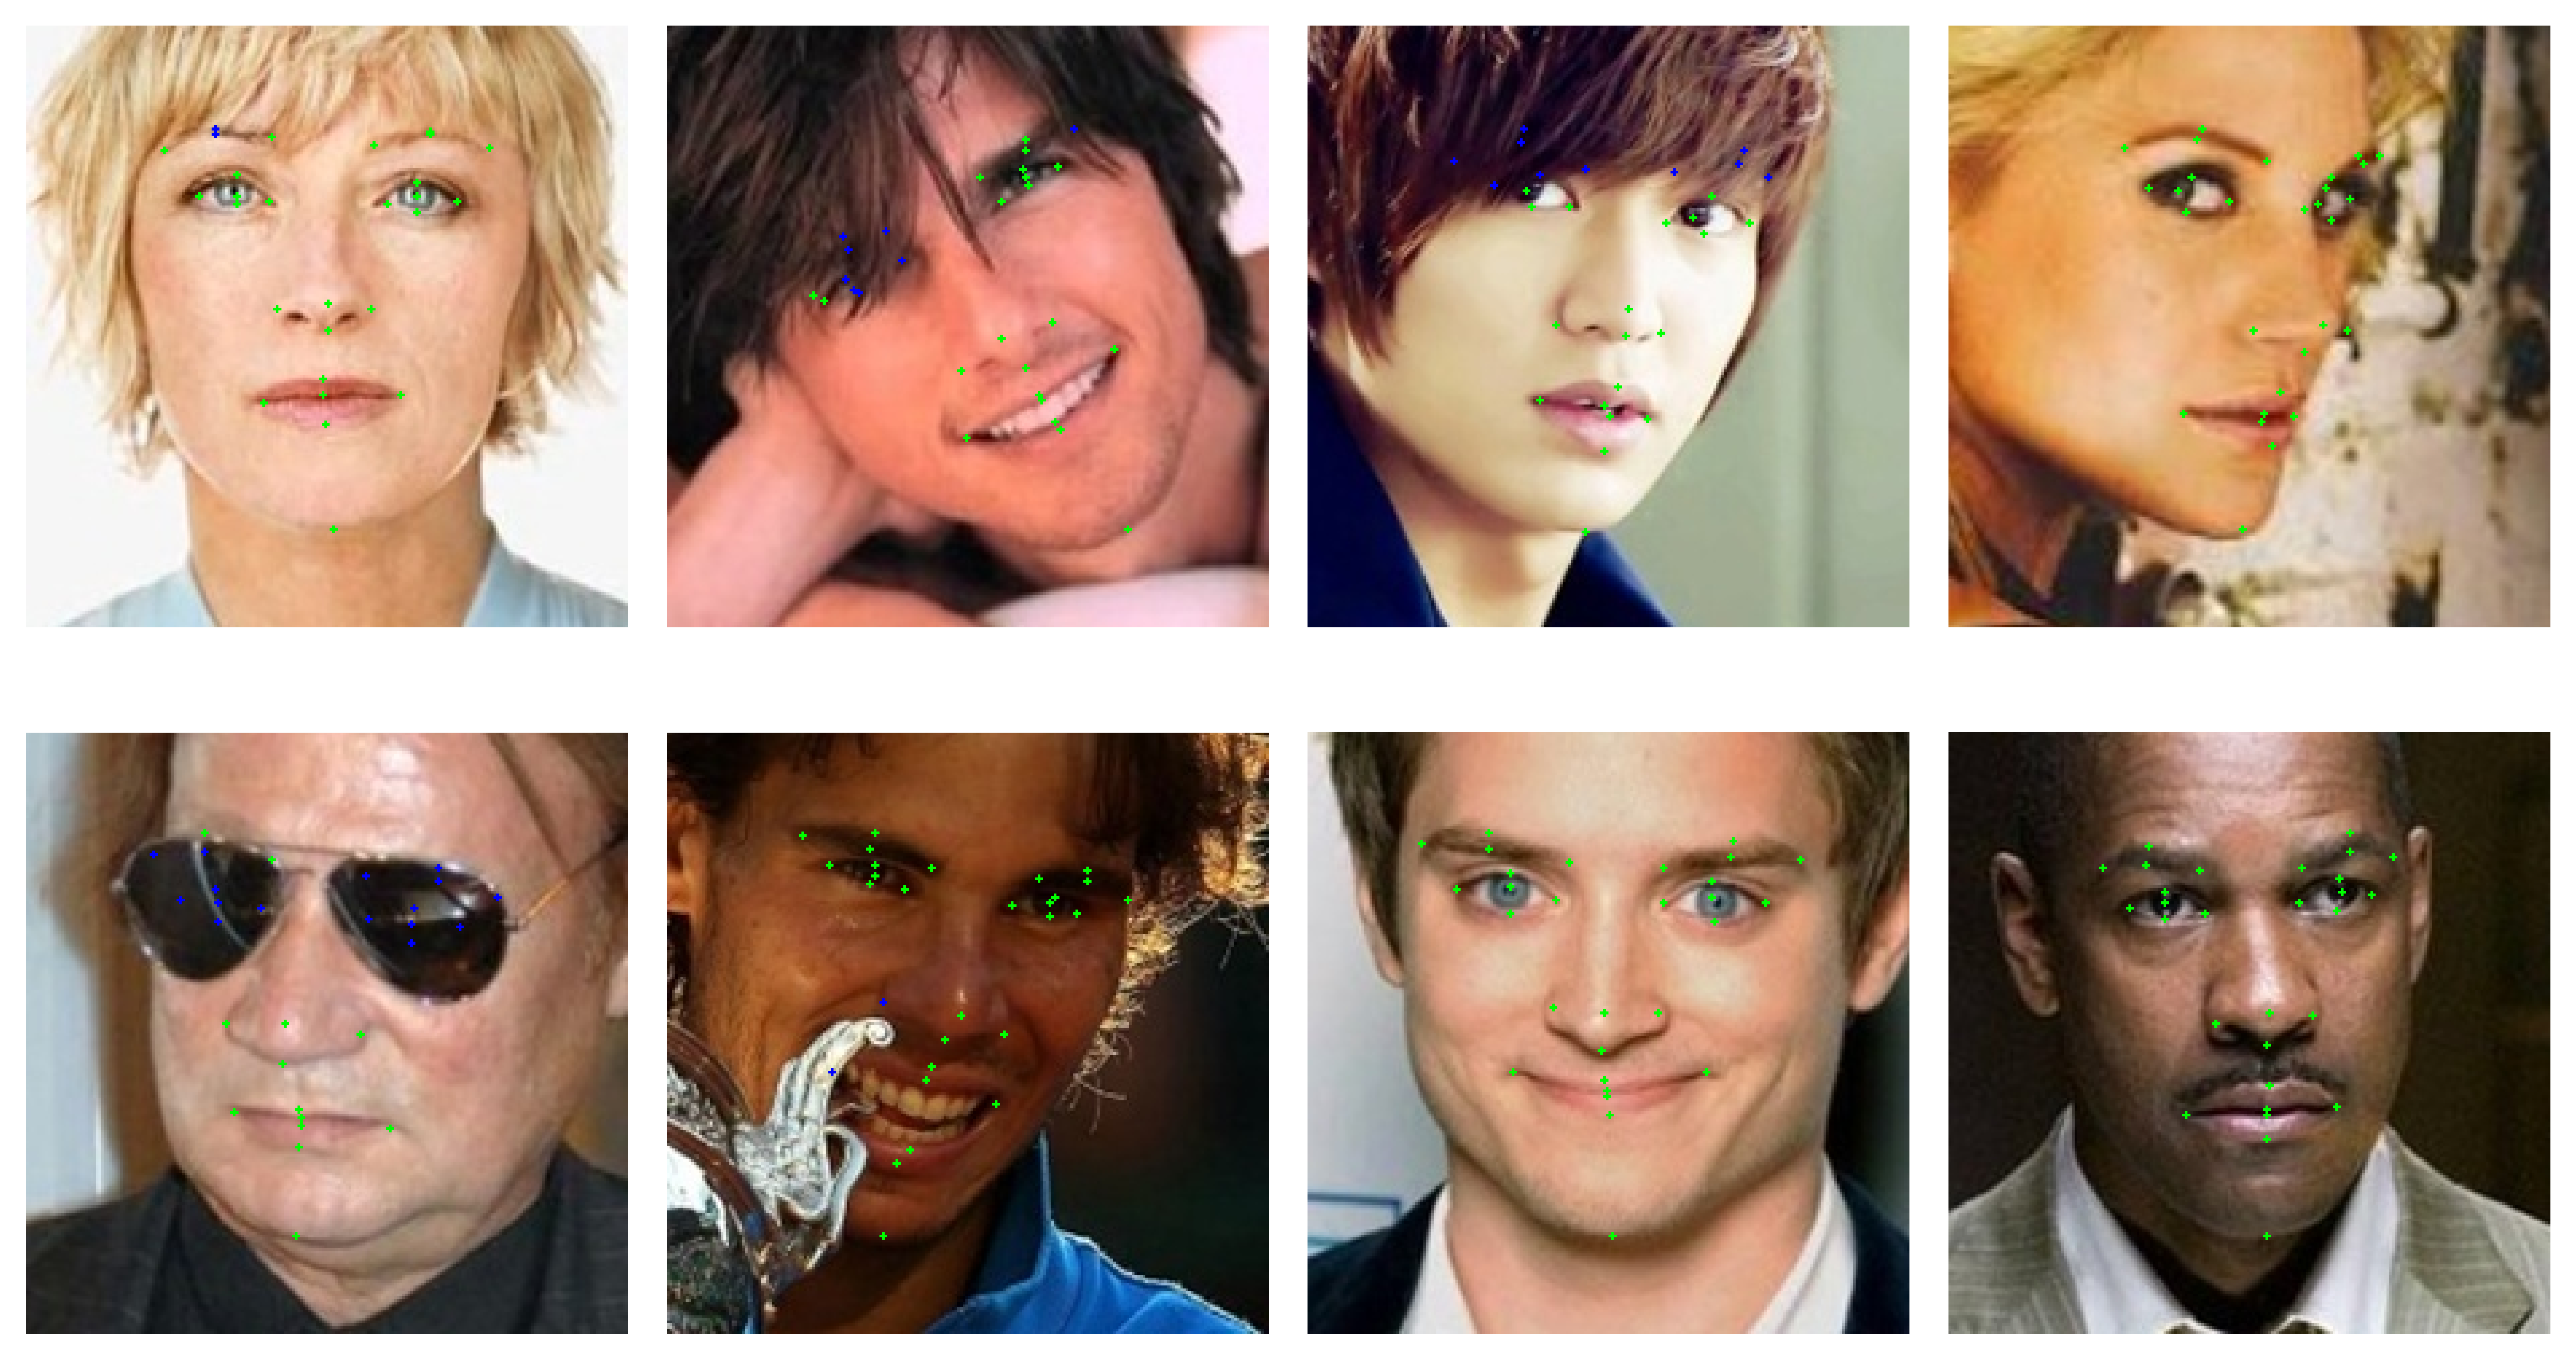

In [6]:
plt.figure(figsize = (10, 6), dpi = 600)
for i in range(8):
    index = np.random.randint(0, len(labels_df))
    image = cv2.imread(os.path.join(dataset_dir, 'Images', labels_df['filename'][index]))[:, :, ::-1] # Convert BGR to RGB
    landmarks = np.array([[labels_df[f'x{point}'][index], labels_df[f'y{point}'][index]] for point in range(29)])
    visibility = np.array([labels_df[f'v{point}'][index] for point in range(29)])
    image_with_landmarks = draw_landmarks(image, landmarks, visibility)
    plt.subplot(2, 4, i+1)
    plt.imshow(image_with_landmarks)
    plt.axis('off')

plt.tight_layout()
plt.savefig(os.path.join('data', 'figures', 'Visibility Detection', 'cofw_sample_images_with_landmarks.png'), dpi = 600)
plt.show()


In [16]:
visibility = labels_df.iloc[:, 1 + 29*2 : 1 + 29*3]

In [17]:
(visibility == 0).sum()

v0     2487
v1     2531
v2     2789
v3     2823
v4     2692
v5     2644
v6     2726
v7     2679
v8     2788
v9     2811
v10    2939
v11    2943
v12    2829
v13    2930
v14    2833
v15    2937
v16    2897
v17    2900
v18    3040
v19    3054
v20    3136
v21    3088
v22    2806
v23    2817
v24    2881
v25    2816
v26    2716
v27    2691
v28    2568
dtype: int64

In [18]:
(visibility == 1).sum().sum()

np.int64(10922)

In [19]:
pos_weight = np.array([(visibility == 0).sum() / (visibility == 1).sum()], dtype = np.float32)

In [20]:
pos_weight 

array([[ 3.502817 ,  3.8003004,  6.8357844,  7.548128 ,  5.3306932,
         4.7811933,  5.787686 ,  5.1718144,  6.816626 ,  7.2823834,
        11.391473 , 11.586615 ,  7.6875   , 10.973783 ,  7.782967 ,
        11.296154 ,  9.656667 ,  9.76431  , 19.363058 , 21.356644 ,
        51.409836 , 28.330275 ,  7.1764708,  7.413158 ,  9.117088 ,
         7.391076 ,  5.6465697,  5.318182 ,  4.0826707]], dtype=float32)